# 12 · Complete Cricket Analytics Pipeline

One notebook from raw files to finished reports: read the data, clean it, score the matches, calculate player statistics, analyse bowling and batting, draw the charts, and write the results to CSV.

Needs: numpy, pandas, matplotlib (`pip install -r notebooks/requirements.txt`).

> Running in Google Colab? Run this once in a new cell first (replace the URL with wherever your copy of the project lives), then run the notebook from the top:
> ```python
> !git clone https://github.com/YOUR-ACCOUNT/pitchvision.git   # or upload and unzip the project folder
> %cd pitchvision
> !pip install -q -r notebooks/requirements.txt
> ```

> About the data. The CSV files in `notebooks/data/` are synthetic: generated by `pitchvision/sample_data.py` with a fixed random seed. The players, matches and numbers are invented so the notebook can run straight away. They are not a real team's results. To use your own data, replace the CSV files with files that have the same columns (see `notebooks/data/DATA_DICTIONARY.md`).

In [1]:
# --- Setup: find the project folder so the shared `pitchvision` package can be imported ---
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "pitchvision").exists():        # the notebook is being run from notebooks/
    ROOT = ROOT.parent
if not (ROOT / "pitchvision").exists():
    raise RuntimeError("Cannot find the 'pitchvision' folder. Open this notebook from inside the PitchVision "
                       "project, or see the Google Colab instructions in notebooks/README.md.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "notebooks" / "data"             # sample CSV files (SYNTHETIC data)
EXPORTS = ROOT / "notebooks" / "exports"       # CSV files written by the notebooks
EXPORTS.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, GREEN, RED, YELLOW = "#0D1310", "#1F6B45", "#B3261E", "#F2C230"
print("Project folder:", ROOT)

Project folder: /Users/sahasreddy/Documents/Cricket


## 1. Settings

Point `INPUT` at a folder with files in the same format as `notebooks/data/` (see `DATA_DICTIONARY.md`) and run the notebook from the top.

In [2]:
from pitchvision import scoring, stats, pitchmap, speed, coach, ml
import datetime as dt

INPUT = DATA                        # change to the folder holding your own CSV files
OUTPUT = EXPORTS / "pipeline"; OUTPUT.mkdir(exist_ok=True)
TEAM_SEASON = "2025"
print("Reading from", INPUT); print("Writing to", OUTPUT)

Reading from /Users/sahasreddy/Documents/Cricket/notebooks/data
Writing to /Users/sahasreddy/Documents/Cricket/notebooks/exports/pipeline


## 2. Ingest and validate

Each table is checked for the columns it needs and for impossible values before anything is calculated.

In [3]:
REQUIRED = {"players": ["name", "role"], "matches": ["match_id", "date", "opponent"],
            "balls": ["match_id", "innings", "striker", "bowler", "runs_bat", "wides", "no_balls"],
            "deliveries": ["player", "x", "y", "date"], "speeds": ["player", "date", "kmh"], "fielding": ["player", "kind", "count"]}
tables, problems = {}, []
for name, cols in REQUIRED.items():
    df = pd.read_csv(INPUT / f"{name}.csv")
    missing = [c for c in cols if c not in df]
    if missing: problems.append(f"{name}.csv is missing columns {missing}")
    tables[name] = df
    print(f"{name:11s} {len(df):6d} rows")
assert not problems, problems

balls = tables["balls"]
checks = {"negative runs": (balls["runs_bat"] < 0).sum(), "runs over 7 off the bat": (balls["runs_bat"] > 7).sum(),
          "wide and no-ball on one ball": ((balls["wides"] > 0) & (balls["no_balls"] > 0)).sum(),
          "pitching point off the pitch": ((balls["x"].abs() > 1.6) | (balls["y"] > 20.12) | (balls["y"] < -1)).sum(),
          "speeds above 200 km/h": (tables["speeds"]["kmh"] > 200).sum()}
print("\nValidation:"); [print(f" - {k}: {v}") for k, v in checks.items()]

players         14 rows
matches          8 rows
balls         1766 rows
deliveries     768 rows
speeds         224 rows
fielding       335 rows

Validation:
 - negative runs: 0
 - runs over 7 off the bat: 0
 - wide and no-ball on one ball: 0
 - pitching point off the pitch: 0
 - speeds above 200 km/h: 0


[None, None, None, None, None]

## 3. Clean

Missing values are counted and handled by rule, never guessed. Rows that cannot be used for a calculation are dropped from that calculation only.

In [4]:
clean_log = []
def log(step, before, after): clean_log.append({"step": step, "rows before": before, "rows after": after, "removed": before - after})

speeds = tables["speeds"].copy(); speeds["date"] = pd.to_datetime(speeds["date"])
n = len(speeds); speeds = speeds.dropna(subset=["kmh"]); speeds = speeds[(speeds["kmh"] > 0) & (speeds["kmh"] < 200)]; log("speed readings with a usable value", n, len(speeds))

deliveries = tables["deliveries"].copy(); n = len(deliveries)
deliveries = deliveries.dropna(subset=["x", "y"]); log("deliveries with a pitching point", n, len(deliveries))
deliveries["length"] = deliveries["y"].apply(pitchmap.classify_length); deliveries["line"] = deliveries["x"].apply(pitchmap.classify_line)

matches = tables["matches"].copy(); matches["date"] = pd.to_datetime(matches["date"])
players = tables["players"]; ours = set(players["name"])
pd.DataFrame(clean_log)

,step,rows before,rows after,removed
0,speed readings with a usable value,224,223,1
1,deliveries with a pitching point,768,762,6


## 4. Score every innings

The scoring engine checks each ball against the Laws. A file that breaks a rule stops here with the match, innings and ball number rather than producing wrong statistics.

In [5]:
try:
    lines = scoring.lines_from_balls(balls.to_dict("records"), max_overs=20)
except scoring.ScoringError as e:
    raise SystemExit(f"The ball-by-ball data breaks a scoring rule: {e}")
cards = lines["innings"]
innings_table = pd.DataFrame([{"match_id": k[0], "innings": k[1], "total": c["total"], "wickets": c["wickets"], "overs": c["overs"],
                               "run_rate": c["run_rate"], "extras": c["extras"]["total"]} for k, c in cards.items()])
print(len(innings_table), "innings scored without a rule being broken")
innings_table.head()

16 innings scored without a rule being broken


,match_id,innings,total,wickets,overs,run_rate,extras
0,1,1,141,4,20.0,7.050000,8
1,1,2,110,10,19.0,5.789474,7
2,2,1,96,10,15.0,6.400000,4
3,2,2,77,10,16.4,4.620000,8
4,3,1,111,9,20.0,5.550000,3


## 5. Player statistics and feature engineering

In [6]:
batting = pd.DataFrame(stats.career_batting([l for l in lines["batting"] if l["player"] in ours])).set_index("player")
bowling = pd.DataFrame(stats.career_bowling([l for l in lines["bowling"] if l["player"] in ours])).set_index("player")
fielding_t = pd.DataFrame(stats.career_fielding(tables["fielding"].to_dict("records"))).set_index("player")

# Derived features per player: how consistent, how boundary-heavy, how accurate in practice, how fast.
batting["median_score"] = [pd.Series([s["runs"] for s in sc]).median() for sc in batting["scores"]]
batting["score_sd"] = [pd.Series([s["runs"] for s in sc]).std(ddof=0) for sc in batting["scores"]]
bowling["dot_pct"] = bowling["dot_pct"].round(1)
practice = deliveries.groupby("player").apply(lambda g: pd.Series(pitchmap.accuracy(g.to_dict("records"), 0.2, 5.2 if g["bowl_type"].iloc[0] == "spin" else 7.0)))[["total", "hit_pct", "spread_x", "spread_y", "consistency_index"]]
spd = speeds[speeds["source"] != "radar"].groupby("player")["kmh"].agg(avg_kmh="mean", max_kmh="max", readings="count")
radar = speeds[speeds["source"] == "radar"].groupby("player")["kmh"].agg(radar_kmh="max")
profile = (players.set_index("name")[["role", "bowl_style"]]
           .join(batting[["innings", "runs", "average", "strike_rate", "highest", "boundary_pct", "median_score", "score_sd"]])
           .join(bowling[["overs", "wickets", "economy", "average", "dot_pct"]], rsuffix="_bowl")
           .join(fielding_t[["catch", "drop", "catch_pct", "run_outs_total"]])
           .join(practice[["hit_pct", "consistency_index"]]).join(spd).join(radar))
profile.round(1).head(8)

/var/folders/9t/b36q0b4n62v1k83dz5btqz8w0000gn/T/ipykernel_28322/4137481800.py:14: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  .join(bowling[["overs", "wickets", "economy", "average", "dot_pct"]], rsuffix="_bowl")


,role,bowl_style,innings,runs,average,strike_rate,highest,boundary_pct,median_score,score_sd,...,catch,drop,catch_pct,run_outs_total,hit_pct,consistency_index,avg_kmh,max_kmh,readings,radar_kmh
name,,,,,,,,,,,,,,,,,,,,,
Arun Mehta,batter,NaN,7.0,120.0,17.1,127.7,41.0,63.3,20.0,15.0,...,5,0,100.0,0,NaN,NaN,NaN,NaN,NaN,NaN
Ben Carter,batter,NaN,6.0,56.0,9.3,109.8,19.0,60.7,10.5,6.3,...,4,1,80.0,3,NaN,NaN,NaN,NaN,NaN,NaN
Dev Patel,wicket_keeper,NaN,8.0,91.0,11.4,115.2,39.0,57.1,6.0,13.1,...,3,0,100.0,1,NaN,NaN,NaN,NaN,NaN,NaN
Ethan Brooks,batter,spin_off,6.0,67.0,11.2,85.9,25.0,44.8,12.0,9.1,...,1,3,25.0,1,15.6,31.5,60.2,64.9,24.0,69.6
Farhan Ali,all_rounder,pace_medium,6.0,115.0,19.2,115.0,32.0,64.3,15.0,7.5,...,3,0,100.0,0,29.0,38.4,91.8,96.9,24.0,106.6
George Hill,all_rounder,spin_leg,7.0,71.0,11.8,93.4,31.0,64.8,4.0,11.0,...,2,2,50.0,1,29.8,34.1,61.7,64.7,24.0,73.3
Harry Singh,batter,NaN,8.0,82.0,11.7,85.4,22.0,61.0,11.5,7.6,...,3,3,50.0,0,NaN,NaN,NaN,NaN,NaN,NaN
Imran Khan,bowler,pace_fast,4.0,38.0,12.7,92.7,16.0,63.2,11.0,6.5,...,7,2,77.8,3,35.4,44.3,102.9,109.0,23.0,118.3


## 6. Bowling analysis

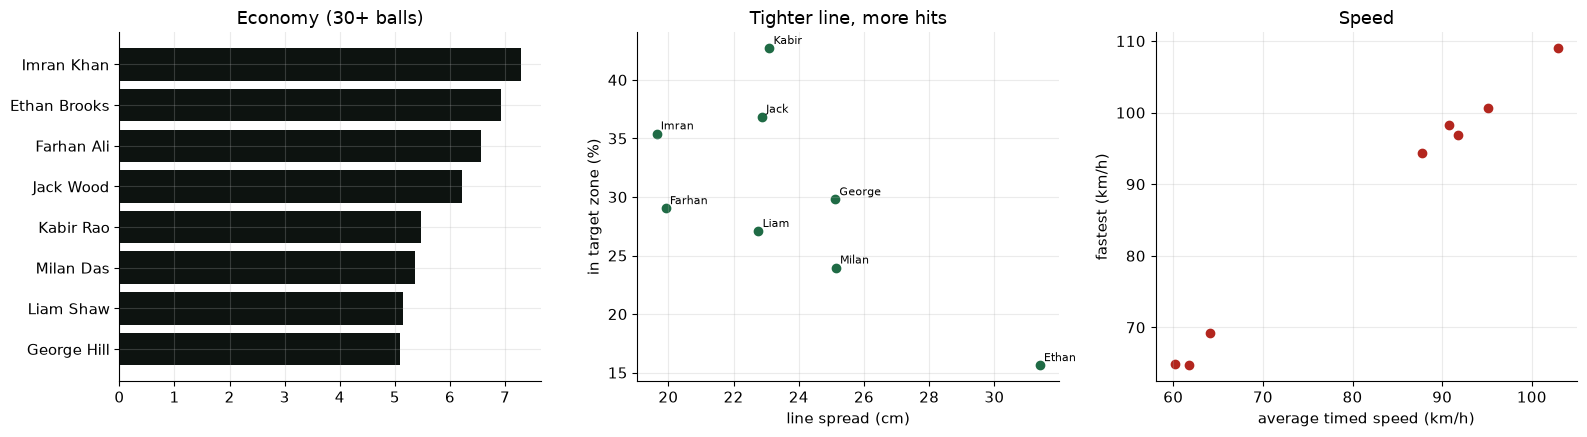

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
b = bowling[bowling["legal_balls"] >= 30].sort_values("economy")
axes[0].barh(b.index, b["economy"], color=INK); axes[0].set_title("Economy (30+ balls)")
axes[1].scatter(practice["spread_x"] * 100, practice["hit_pct"], color=GREEN)
for n_, r in practice.iterrows(): axes[1].annotate(n_.split()[0], (r["spread_x"] * 100, r["hit_pct"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
axes[1].set_xlabel("line spread (cm)"); axes[1].set_ylabel("in target zone (%)"); axes[1].set_title("Tighter line, more hits")
axes[2].scatter(spd["avg_kmh"], spd["max_kmh"], color=RED); axes[2].set_xlabel("average timed speed (km/h)"); axes[2].set_ylabel("fastest (km/h)"); axes[2].set_title("Speed")
plt.tight_layout(); plt.show()

## 7. Batting analysis

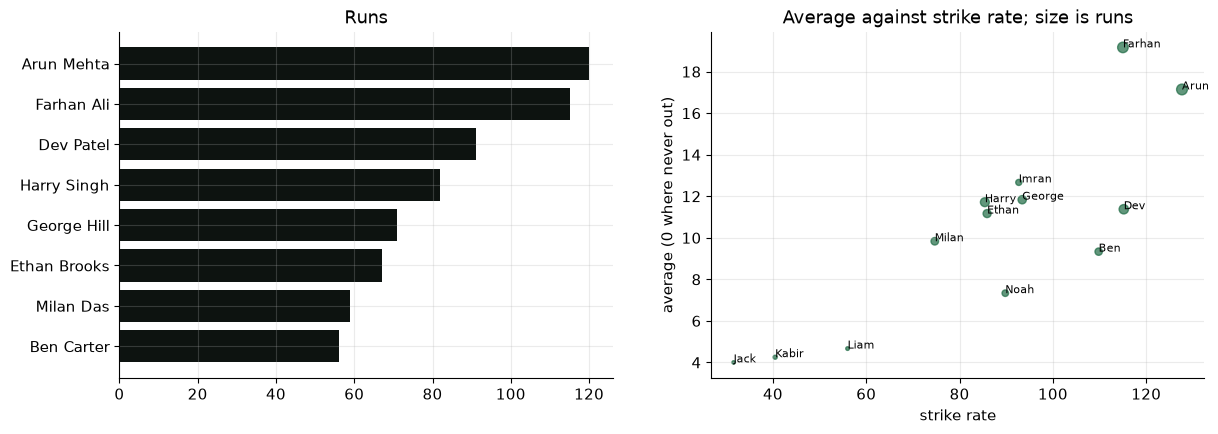

Team against pace: 436 runs from 511 balls, strike rate 85
Team against spin: 350 runs from 337 balls, strike rate 104


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
b = batting.sort_values("runs").tail(8)
axes[0].barh(b.index, b["runs"], color=INK); axes[0].set_title("Runs")
axes[1].scatter(batting["strike_rate"], batting["average"].fillna(0), s=batting["runs"] / 2, color=GREEN, alpha=0.7)
for n_, r in batting.iterrows(): axes[1].annotate(n_.split()[0], (r["strike_rate"], r["average"] if pd.notna(r["average"]) else 0), fontsize=8)
axes[1].set_xlabel("strike rate"); axes[1].set_ylabel("average (0 where never out)"); axes[1].set_title("Average against strike rate; size is runs")
plt.show()

team_splits = {"pace": [0, 0], "spin": [0, 0]}
for n_ in ours:
    for k, d in stats.batting_splits(balls.to_dict("records"), n_)["bowl_type"].items():
        team_splits[k][0] += d["runs"]; team_splits[k][1] += d["balls"]
for k, (r, bl) in team_splits.items(): print(f"Team against {k}: {r} runs from {bl} balls, strike rate {r / bl * 100:.0f}")

## 8. Reports

A one-page report for each player: their figures, their coaching recommendations with the evidence, and the thresholds used.

In [9]:
ctx = {"players": [{"id": n, "name": n, "role": r["role"]} for n, r in players.set_index("name").iterrows()],
       "batting": [{**r, "name": r["player"]} for r in stats.career_batting([l for l in lines["batting"] if l["player"] in ours])],
       "bowling": [{**r, "name": r["player"]} for r in stats.career_bowling([l for l in lines["bowling"] if l["player"] in ours])],
       "fielding": stats.career_fielding(tables["fielding"].to_dict("records")),
       "accuracy": {n_: pitchmap.accuracy(g.to_dict("records"), 0.2, 7.0) for n_, g in deliveries.groupby("player")},
       "speeds": {n_: g.sort_values("date")[["date", "kmh"]].to_dict("records") for n_, g in speeds.groupby("player")},
       "splits": {n_: stats.batting_splits(balls.to_dict("records"), n_) for n_ in ours}}

def report(name):
    p = profile.loc[name]; out = [f"PLAYER REPORT: {name}", f"Role: {p['role']}", ""]
    if pd.notna(p["runs"]): out.append(f"Batting: {int(p['innings'])} innings, {int(p['runs'])} runs, average {p['average']:.1f}" if pd.notna(p["average"]) else f"Batting: {int(p['innings'])} innings, {int(p['runs'])} runs, never out")
    if pd.notna(p["overs"]): out.append(f"Bowling: {p['overs']} overs, {int(p['wickets'])} wickets, economy {p['economy']:.2f}")
    if pd.notna(p["catch_pct"]): out.append(f"Fielding: {int(p['catch'])} catches, {p['catch_pct']:.0f}% of chances")
    out.append(""); recs = coach.player_recommendations(ctx, name)
    out.append("Recommendations:" if recs else "No recommendation crosses a coaching threshold.")
    for r in recs: out += [f" - {r['area']}: {r['recommendation']}", f"     evidence: {r['evidence']}"]
    return "\n".join(out)

print(report("Imran Khan"))
(OUTPUT / "player_reports.txt").write_text("\n\n".join(report(n) for n in profile.index))

PLAYER REPORT: Imran Khan
Role: bowler

Batting: 4 innings, 38 runs, average 12.7
Bowling: 14.0 overs, 7 wickets, economy 7.29
Fielding: 7 catches, 78% of chances

Recommendations:
 - Bowling accuracy: Targeted line-and-length practice.
     evidence: 35% of 96 recorded deliveries landed in the target zone (below 40%).
 - Starting an innings: You are often out before reaching 10.
     evidence: Out for under 10 in 2 of 4 innings.
 - Bowling economy: You concede more per over than the team rate; work on a stock ball you can land under pressure.
     evidence: Economy 7.29 against a team economy of 5.95 (14.0 overs bowled).
 - Strike rotation: A high share of the balls you face are dot balls.
     evidence: 63% dot balls from 41 balls faced (above 60%).


9472

## 9. A model, honestly evaluated

In [10]:
model = ml.train_dot_ball_model(balls[balls["batting_team"].str.contains("synthetic")].to_dict("records"), synthetic=True)
if model["status"] == "ok":
    print(pd.DataFrame(model["results"]).round(3).to_string(index=False)); print(model["conclusion"]); print(model["caveat"])
else:
    print(model["reason"])

                                            model  accuracy_mean  accuracy_std  roc_auc_mean  roc_auc_std
baseline (always predict the most common outcome)          0.583         0.001         0.500        0.000
                              logistic regression          0.576         0.009         0.572        0.015
                                    random forest          0.589         0.030         0.603        0.014
The model ranks deliveries better than chance (ROC-AUC above 0.5 by more than two standard deviations).
Trained and tested on SYNTHETIC data: these scores only show the pipeline works.


## 10. Export

In [11]:
profile.round(3).to_csv(OUTPUT / "player_profiles.csv")
innings_table.round(3).to_csv(OUTPUT / "innings.csv", index=False)
pd.DataFrame(clean_log).to_csv(OUTPUT / "cleaning_log.csv", index=False)
deliveries.to_csv(OUTPUT / "deliveries_classified.csv", index=False)
(pd.DataFrame(ctx["batting"]).drop(columns=["scores"]).round(3)).to_csv(OUTPUT / "batting.csv", index=False)
(pd.DataFrame(ctx["bowling"]).drop(columns=["spells"]).round(3)).to_csv(OUTPUT / "bowling.csv", index=False)
for f in sorted(OUTPUT.iterdir()): print(f"{f.name:28s} {f.stat().st_size / 1024:7.1f} KB")
print("\nRun finished", dt.datetime.now().strftime("%Y-%m-%d %H:%M"))

batting.csv                      1.1 KB
bowling.csv                      0.8 KB
cleaning_log.csv                 0.1 KB
deliveries_classified.csv       48.9 KB
innings.csv                      0.4 KB
player_profiles.csv              1.9 KB
player_reports.txt               9.2 KB

Run finished 2026-11-11 21:14


## Summary

### Key findings
- Every table is checked before use, and the scoring engine stops the run if a ball breaks a rule.
- Player profiles join batting, bowling, fielding, practice accuracy and speed into one table, and a plain-text report for each player lists its evidence.
- The results are written to `notebooks/exports/pipeline/` as CSV files.

### Interpretation
The pipeline gives a team a repeatable way to refresh its statistics: replace the input files, run the notebook from the top and read the reports.

### Limitations
- Column names must match the data dictionary. A file in another format needs a short mapping step before this one.
- Cleaning drops unusable rows from each calculation but never invents values.
- Statistics from a few matches are noisy; the reports show counts so this stays visible.
- The sample files are synthetic.

### How this notebook connects to the application
The application runs the same steps on a database instead of CSV files: `services.collect` plays the role of sections 2 to 4, and the Overview, Team Hub, Match Center and AI Coach call the shared `stats`, `scoring`, `pitchmap`, `coach` and `ml` functions used above.